# IPL Bowler Performance Analysis

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

matches = pd.read_csv("../data/cleaned/matches_clean.csv")
deliveries = pd.read_csv("../data/cleaned/deliveries_clean.csv")

## Business Question 1

Who are the leading wicket-takers in IPL history?

In [55]:
deliveries['dismissal_kind'].unique()

<StringArray>
[                    nan,                'caught',                'bowled',
               'run out',                   'lbw',          'retired hurt',
               'stumped',     'caught and bowled',            'hit wicket',
 'obstructing the field',           'retired out']
Length: 11, dtype: str

In [56]:
bowler_wickets = deliveries[~deliveries['dismissal_kind'].isin(['run out', 'retired hurt', 'obstructing the field', 'retired out']) 
    & deliveries['is_wicket'] == 1]

In [57]:
wickets = bowler_wickets.groupby('bowler')['is_wicket'].size().sort_values(ascending=False)

In [58]:
wicket_stats = pd.DataFrame({
    'Wickets' : wickets
})

In [59]:
wicket_stats.head(10)

,Wickets
bowler,
YS Chahal,205
PP Chawla,192
DJ Bravo,183
B Kumar,181
R Ashwin,180
SP Narine,180
A Mishra,174
SL Malinga,170
JJ Bumrah,168


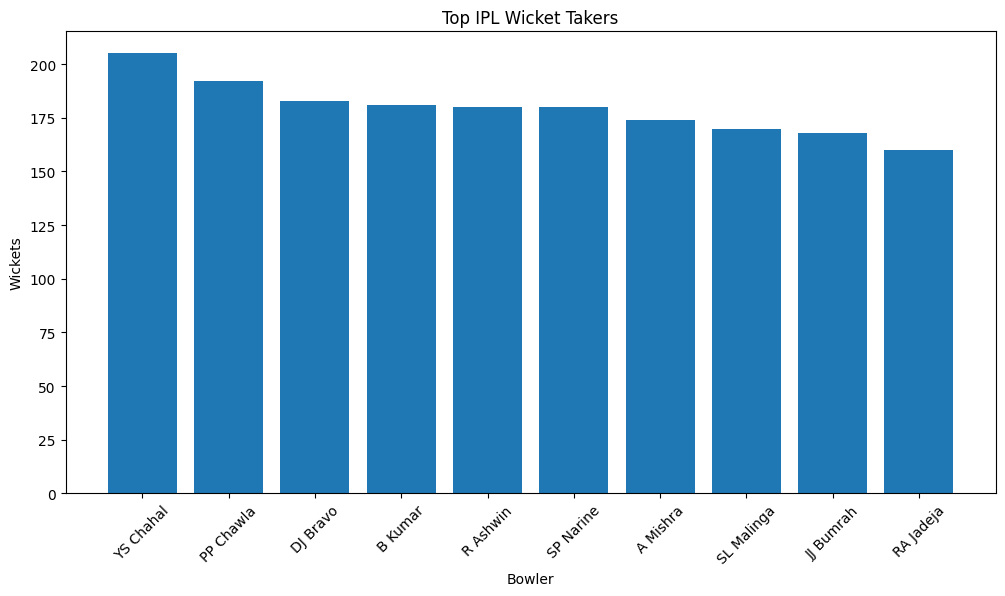

In [60]:
top_wickets = wickets.head(10)

plt.figure(figsize=(12,6))

plt.bar(
    top_wickets.index,
    top_wickets.values
)

plt.title('Top IPL Wicket Takers')

plt.xlabel('Bowler')
plt.ylabel('Wickets')

plt.xticks(rotation=45)

plt.show()

## Insight

Wickets are one of the most important indicators of bowling success in T20 cricket.

This analysis highlights bowlers who have consistently taken wickets across multiple IPL seasons.

## Business Question 2

Which bowlers have the best economy rate in IPL history?

In [61]:
deliveries['extras_type'].unique()

<StringArray>
['legbyes', nan, 'wides', 'byes', 'noballs', 'penalty']
Length: 6, dtype: str

In [62]:
runs_conceded = (
    deliveries['batsman_runs']
    + 
    np.where(deliveries['extras_type'].isin(['wides', 'noballs']), deliveries['extra_runs'], 0)
)    
runs_conceded = runs_conceded.groupby(deliveries['bowler']).sum()

In [63]:
balls_bowled = deliveries[~deliveries['extras_type'].isin(['wides', 'noballs'])].groupby('bowler').size()

In [64]:
economy_stats = pd.DataFrame({
    'Runs_Conceded': runs_conceded,
    'Balls_Bowled': balls_bowled
})
economy_stats = economy_stats.fillna(0)

In [65]:
economy_stats['Economy'] = (economy_stats['Runs_Conceded'] / economy_stats['Balls_Bowled']) * 6

In [66]:
economy_stats['Wickets'] = wickets
economy_stats = economy_stats.fillna(0)

In [67]:
economy_stats = economy_stats[economy_stats['Balls_Bowled'] >= 600]

In [68]:
economy_stats.sort_values(by='Economy').head(20)

,Runs_Conceded,Balls_Bowled,Economy,Wickets
bowler,,,,
A Kumble,1058,965,6.578238,45.0
M Muralitharan,1706,1528,6.698953,64.0
SP Narine,4582,4081,6.736584,180.0
DL Vettori,879,777,6.787645,28.0
Rashid Khan,3267,2872,6.825209,149.0
J Botha,800,694,6.916427,25.0
DW Steyn,2523,2182,6.937672,97.0
R Sharma,1086,928,7.021552,40.0
MM Ali,893,758,7.068602,35.0


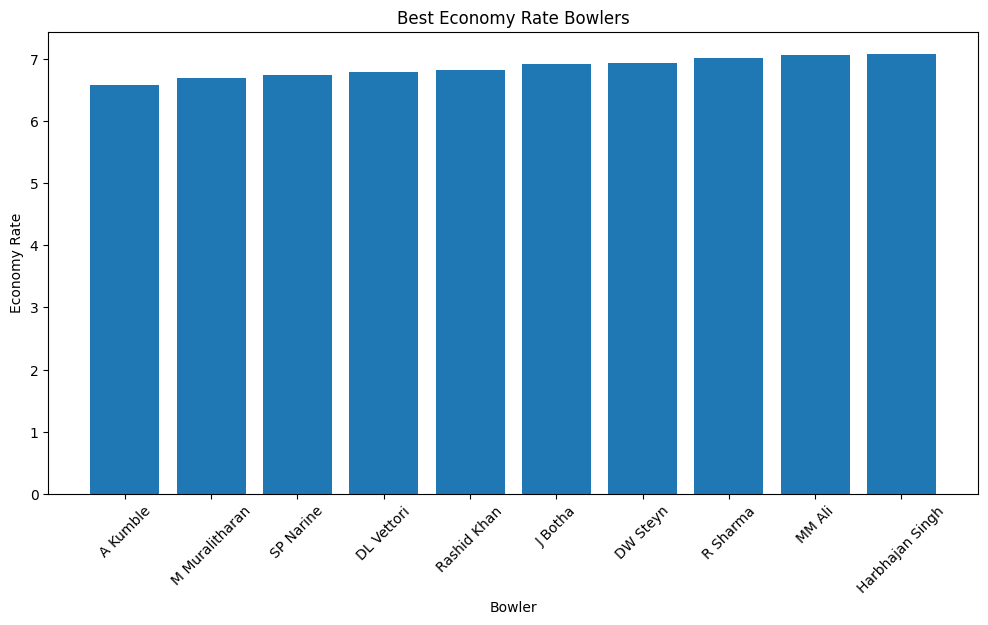

In [69]:
top_economy = (economy_stats.sort_values(by='Economy').head(10))

plt.figure(figsize=(12,6))

plt.bar(
    top_economy.index,
    top_economy['Economy']
)

plt.title('Best Economy Rate Bowlers')

plt.xlabel('Bowler')
plt.ylabel('Economy Rate')

plt.xticks(rotation=45)

plt.show()

## Insight

Economy Rate measures a bowler's ability to restrict scoring.

A lower economy rate indicates better run control and greater effectiveness in limiting opposition scoring opportunities.

## Business Question 3

Which bowlers take wickets most efficiently?

In [70]:
strike_rate_stats = pd.DataFrame({
    'Balls_Bowled': balls_bowled,
    'Wickets': wickets
})

strike_rate_stats = strike_rate_stats.fillna(0)

In [71]:
strike_rate_stats = strike_rate_stats[strike_rate_stats['Wickets'] > 0]

In [72]:
strike_rate_stats['Bowling_Strike_Rate'] = (
    strike_rate_stats['Balls_Bowled']
    /
    strike_rate_stats['Wickets']
)

In [73]:
strike_rate_stats = strike_rate_stats[strike_rate_stats['Balls_Bowled'] >= 600]

In [74]:
strike_rate_stats.sort_values(by='Bowling_Strike_Rate').head(20)

,Balls_Bowled,Wickets,Bowling_Strike_Rate
bowler,,,
AD Russell,1697,115.0,14.756522
K Rabada,1829,120.0,15.241667
HV Patel,2162,135.0,16.014815
Imran Tahir,1316,82.0,16.048780
MA Starc,831,51.0,16.294118
AJ Tye,685,42.0,16.309524
SL Malinga,2828,170.0,16.635294
S Aravind,760,45.0,16.888889
DJ Bravo,3120,183.0,17.049180


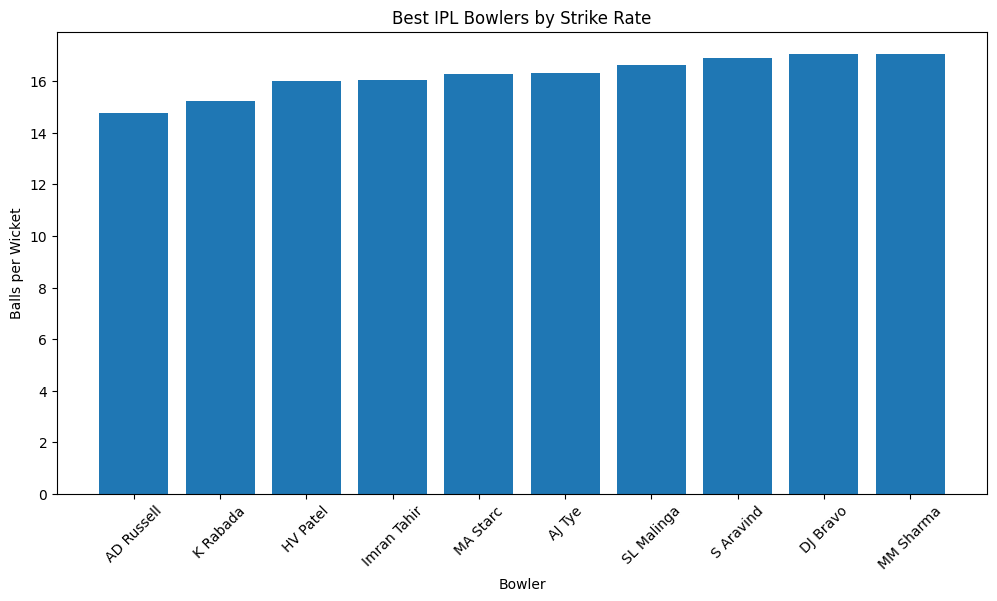

In [75]:
top_sr_bowlers = (strike_rate_stats.sort_values(by='Bowling_Strike_Rate').head(10))

plt.figure(figsize=(12,6))

plt.bar(
    top_sr_bowlers.index,
    top_sr_bowlers['Bowling_Strike_Rate']
)

plt.title('Best IPL Bowlers by Strike Rate')

plt.xlabel('Bowler')
plt.ylabel('Balls per Wicket')

plt.xticks(rotation=45)

plt.show()

## Insight

Bowling Strike Rate measures wicket-taking efficiency.

A lower strike rate indicates that a bowler takes wickets more frequently, making them valuable as attacking or strike bowlers.

## Business Question 4

Which bowlers build pressure through dot balls?

In [76]:
dot_balls = (deliveries[deliveries['total_runs'] == 0].groupby('bowler').size())

In [77]:
dot_ball_stats = pd.DataFrame({
    'Balls_Bowled': balls_bowled,
    'Dot_Balls': dot_balls
})

dot_ball_stats = dot_ball_stats.fillna(0)

In [78]:
dot_ball_stats['Dot_Ball_%'] = (
    dot_ball_stats['Dot_Balls']
    /
    dot_ball_stats['Balls_Bowled']
) * 100

In [79]:
dot_ball_stats = dot_ball_stats[dot_ball_stats['Balls_Bowled'] >= 600]

In [80]:
dot_ball_stats.sort_values(by='Dot_Ball_%',ascending=False).head(20)

,Balls_Bowled,Dot_Balls,Dot_Ball_%
bowler,,,
DW Steyn,2182,1019.0,46.700275
S Sreesanth,880,399.0,45.340909
JC Archer,947,420.0,44.350581
DP Nannes,646,285.0,44.117647
RJ Harris,832,364.0,43.750000
MM Patel,1355,590.0,43.542435
M Morkel,1629,708.0,43.462247
MG Johnson,1235,535.0,43.319838
JR Hazlewood,603,259.0,42.951907


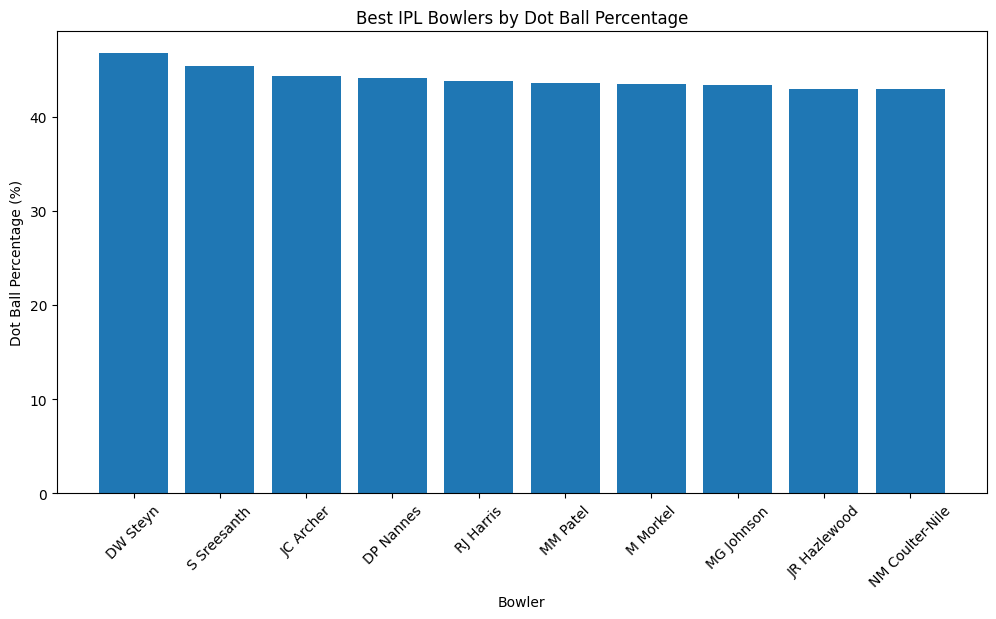

In [81]:
top_dot = (dot_ball_stats.sort_values(by='Dot_Ball_%', ascending=False).head(10))

plt.figure(figsize=(12,6))

plt.bar(
    top_dot.index,
    top_dot['Dot_Ball_%']
)

plt.title('Best IPL Bowlers by Dot Ball Percentage')

plt.xlabel('Bowler')
plt.ylabel('Dot Ball Percentage (%)')

plt.xticks(rotation=45)

plt.show()

## Insight

Dot Ball Percentage measures a bowler's ability to restrict scoring opportunities.

A higher value indicates that the bowler consistently creates pressure by preventing runs.

## Business Question 5

Which bowlers perform best in death overs (16-20)?

In [82]:
death_overs = deliveries[deliveries['over'].between(16, 20)].copy()

In [83]:
death_wickets = death_overs[~death_overs['dismissal_kind'].isin([
    'run out',
    'retired hurt',
    'obstructing the field',
    'retired out'
])
    & (death_overs['is_wicket'] == 1)
]

In [84]:
death_wicket_count = (death_wickets.groupby('bowler').size())

In [85]:
death_runs = (
    death_overs['batsman_runs']
    +
    np.where(death_overs['extras_type'].isin(['wides', 'noballs']), death_overs['extra_runs'], 0)
)

death_runs = (death_runs.groupby(death_overs['bowler']).sum())

In [86]:
death_balls = (death_overs[ ~death_overs['extras_type'].isin(['wides', 'noballs'])].groupby('bowler').size())

In [87]:
death_stats = pd.DataFrame({
    'Balls_Bowled': death_balls,
    'Runs_Conceded': death_runs,
    'Wickets': death_wicket_count
})

death_stats = death_stats.fillna(0)

In [88]:
death_stats['Death_Economy'] = (
    death_stats['Runs_Conceded']
    /
    death_stats['Balls_Bowled']
) * 6

In [89]:
death_stats = death_stats[death_stats['Wickets'] > 0]

death_stats['Death_Strike_Rate'] = (
    death_stats['Balls_Bowled']
    /
    death_stats['Wickets']
)

In [90]:
death_stats = death_stats[death_stats['Balls_Bowled'] >= 120]

In [91]:
death_stats.sort_values(by='Wickets',ascending=False).head(20)

,Balls_Bowled,Runs_Conceded,Wickets,Death_Economy,Death_Strike_Rate
bowler,,,,,
DJ Bravo,1115,1810,102.0,9.739910,10.931373
SL Malinga,917,1196,90.0,7.825518,10.188889
B Kumar,1167,1838,85.0,9.449871,13.729412
JJ Bumrah,1115,1560,80.0,8.394619,13.937500
HV Patel,613,1046,63.0,10.238173,9.730159
MM Sharma,666,1131,61.0,10.189189,10.918033
SP Narine,739,985,60.0,7.997294,12.316667
Mohammed Shami,567,1009,58.0,10.677249,9.775862
CH Morris,586,836,55.0,8.559727,10.654545


In [92]:
death_stats.sort_values(by='Death_Economy').head(20)

,Balls_Bowled,Runs_Conceded,Wickets,Death_Economy,Death_Strike_Rate
bowler,,,,,
DE Bollinger,210,263,21.0,7.514286,10.000000
Rashid Khan,312,403,26.0,7.750000,12.000000
SL Malinga,917,1196,90.0,7.825518,10.188889
SP Narine,739,985,60.0,7.997294,12.316667
M Pathirana,205,283,22.0,8.282927,9.318182
SW Tait,126,175,12.0,8.333333,10.500000
AR Patel,202,282,16.0,8.376238,12.625000
JJ Bumrah,1115,1560,80.0,8.394619,13.937500
DP Nannes,184,258,12.0,8.413043,15.333333


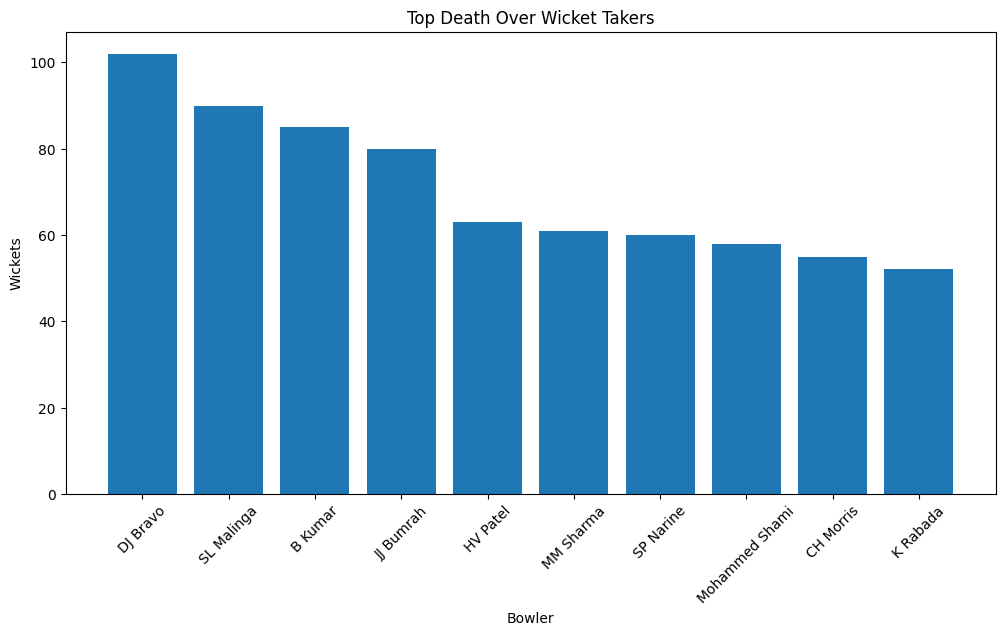

In [93]:
top_death = (death_stats.sort_values(by='Wickets', ascending=False).head(10))

plt.figure(figsize=(12,6))

plt.bar(
    top_death.index,
    top_death['Wickets']
)

plt.title('Top Death Over Wicket Takers')

plt.xlabel('Bowler')
plt.ylabel('Wickets')

plt.xticks(rotation=45)

plt.show()

## Insight

Death overs are the most challenging phase for bowlers due to aggressive batting intent.

Bowlers who maintain low economy rates while taking wickets in overs 16-20 are among the most valuable assets in T20 cricket.

## Business Question 6

Who are the most impactful IPL bowlers?

In [94]:
bowler_impact = pd.DataFrame()

bowler_impact['Wickets'] = wicket_stats['Wickets']
bowler_impact['Economy'] = economy_stats['Economy']
bowler_impact['Strike_Rate'] = strike_rate_stats['Bowling_Strike_Rate']
bowler_impact['Dot_Ball_%'] = dot_ball_stats['Dot_Ball_%']

bowler_impact = bowler_impact.fillna(0)

In [95]:
bowler_impact = bowler_impact[bowler_impact['Wickets'] >= 20]

In [96]:
for col in ['Wickets', 'Dot_Ball_%'] :
    bowler_impact[col + '_Score'] = (
        (
            bowler_impact[col] - bowler_impact[col].min()
        )
        /
        (
            bowler_impact[col].max() - bowler_impact[col].min()
        )
    ) * 100

In [97]:
for col in ['Economy', 'Strike_Rate']:

    bowler_impact[col + '_Score'] = (
        (
            bowler_impact[col].max()
            -
            bowler_impact[col]
        )
        /
        (
            bowler_impact[col].max()
            -
            bowler_impact[col].min()
        )
    ) * 100

In [98]:
bowler_impact['Impact_Score'] = (
      bowler_impact['Wickets_Score'] * 0.40
    + bowler_impact['Economy_Score'] * 0.30
    + bowler_impact['Strike_Rate_Score'] * 0.20
    + bowler_impact['Dot_Ball_%_Score'] * 0.10
)

In [99]:
bowler_impact.sort_values(by='Impact_Score',ascending=False).head(20)

,Wickets,Economy,Strike_Rate,Dot_Ball_%,Wickets_Score,Dot_Ball_%_Score,Economy_Score,Strike_Rate_Score,Impact_Score
bowler,,,,,,,,,
YS Chahal,205,7.842090,17.175610,33.910821,100.000000,72.613750,18.758696,53.660235,63.621031
SL Malinga,170,7.137199,16.635294,40.452617,81.081081,86.621796,26.061118,55.118005,59.936549
SP Narine,180,6.736584,22.672222,38.446459,86.486486,82.325980,30.211352,38.830384,59.656675
PP Chawla,192,7.960519,20.052083,34.415584,92.972973,73.694608,17.531811,45.899514,58.998096
B Kumar,181,7.563683,21.602210,41.739130,87.027027,89.376627,21.642899,41.717275,58.584798
JJ Bumrah,168,7.303415,18.303571,39.934959,80.000000,85.513328,24.339187,50.616996,57.976488
A Mishra,174,7.377633,19.373563,35.152774,83.243243,75.273162,23.570313,47.730160,57.441740
DJ Bravo,183,8.384615,17.049180,31.987179,88.108108,68.494628,13.138327,54.001341,56.834472
R Ashwin,180,7.120690,25.133333,34.305924,86.486486,73.459790,26.232154,32.190310,56.248282


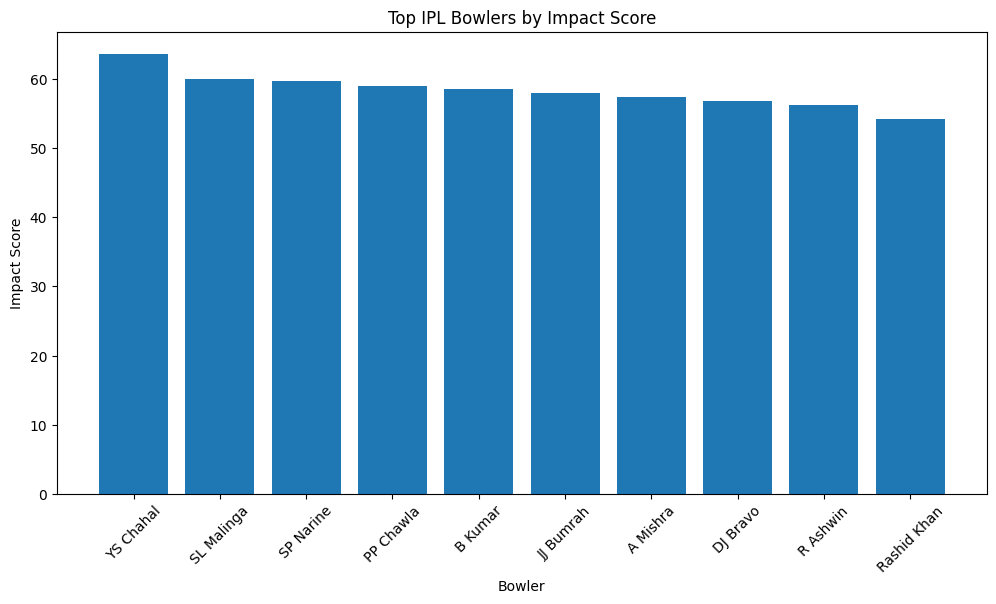

In [100]:
top_bowlers = (bowler_impact.sort_values(by='Impact_Score', ascending=False).head(10))

plt.figure(figsize=(12,6))

plt.bar(
    top_bowlers.index,
    top_bowlers['Impact_Score']
)

plt.title('Top IPL Bowlers by Impact Score')

plt.xlabel('Bowler')
plt.ylabel('Impact Score')

plt.xticks(rotation=45)

plt.show()

## Insight

The Bowler Impact Score combines wicket-taking ability, economy, strike rate, and pressure creation into a single evaluation metric.

This provides a balanced assessment of overall bowling performance rather than relying on a single statistic.